In [62]:
import utils
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

In [65]:
df['CompTotal'].value_counts()

CompTotal
0.0          751
100000.0     705
120000.0     603
60000.0      587
150000.0     522
            ... 
896400.0       1
40497.0        1
4212980.0      1
653000.0       1
449000.0       1
Name: count, Length: 2678, dtype: int64

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: distribución de Age
axes[0].hist(
    df['Age'].dropna(),
    bins=15,
    edgecolor='black'
)
axes[0].set_title('Distribución de edades')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Frecuencia')

# Gráfico 2: CompTotal hasta el percentil 90
comp = df['CompTotal'].dropna()
limite = comp.quantile(0.90)

axes[1].hist(
    comp[comp <= limite],
    bins=15,
    edgecolor='black'
)
axes[1].set_title('Compensación total (hasta P90)')
axes[1].set_xlabel('Compensación anual')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [ ]:
import math
def graficar_histogramas(
    df,
    columnas,
    extras="",
    bins=15,
    ncols=3,
    figsize_por_grafico=(12, 10),
):
    # Seleccionamos únicamente las columnas numéricas solicitadas
    datos = df[columnas].select_dtypes(include='number')

    # Cantidad de gráficos y distribución de la cuadrícula
    n = len(datos.columns)

    if n == 0:
        print("No hay columnas numéricas para graficar.")
        return

    nrows = math.ceil(n / ncols)

    ancho, alto = figsize_por_grafico
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ancho * ncols, alto * nrows),
        squeeze=False
    )

    # Graficamos cada columna en su propio eje
    for ax, columna in zip(axes.flat, datos.columns):
        ax.hist(
            datos[columna].dropna(),
            bins=bins,
            edgecolor='black'
        )
        ax.set_title(columna)
        ax.set_ylabel('Frecuencia')

    # Ocultamos los espacios que quedaron vacíos
    for ax in axes.flat[n:]:
        ax.set_visible(False)

    if extras:
        for i in extras:
            i()

    plt.tight_layout()
    plt.show()

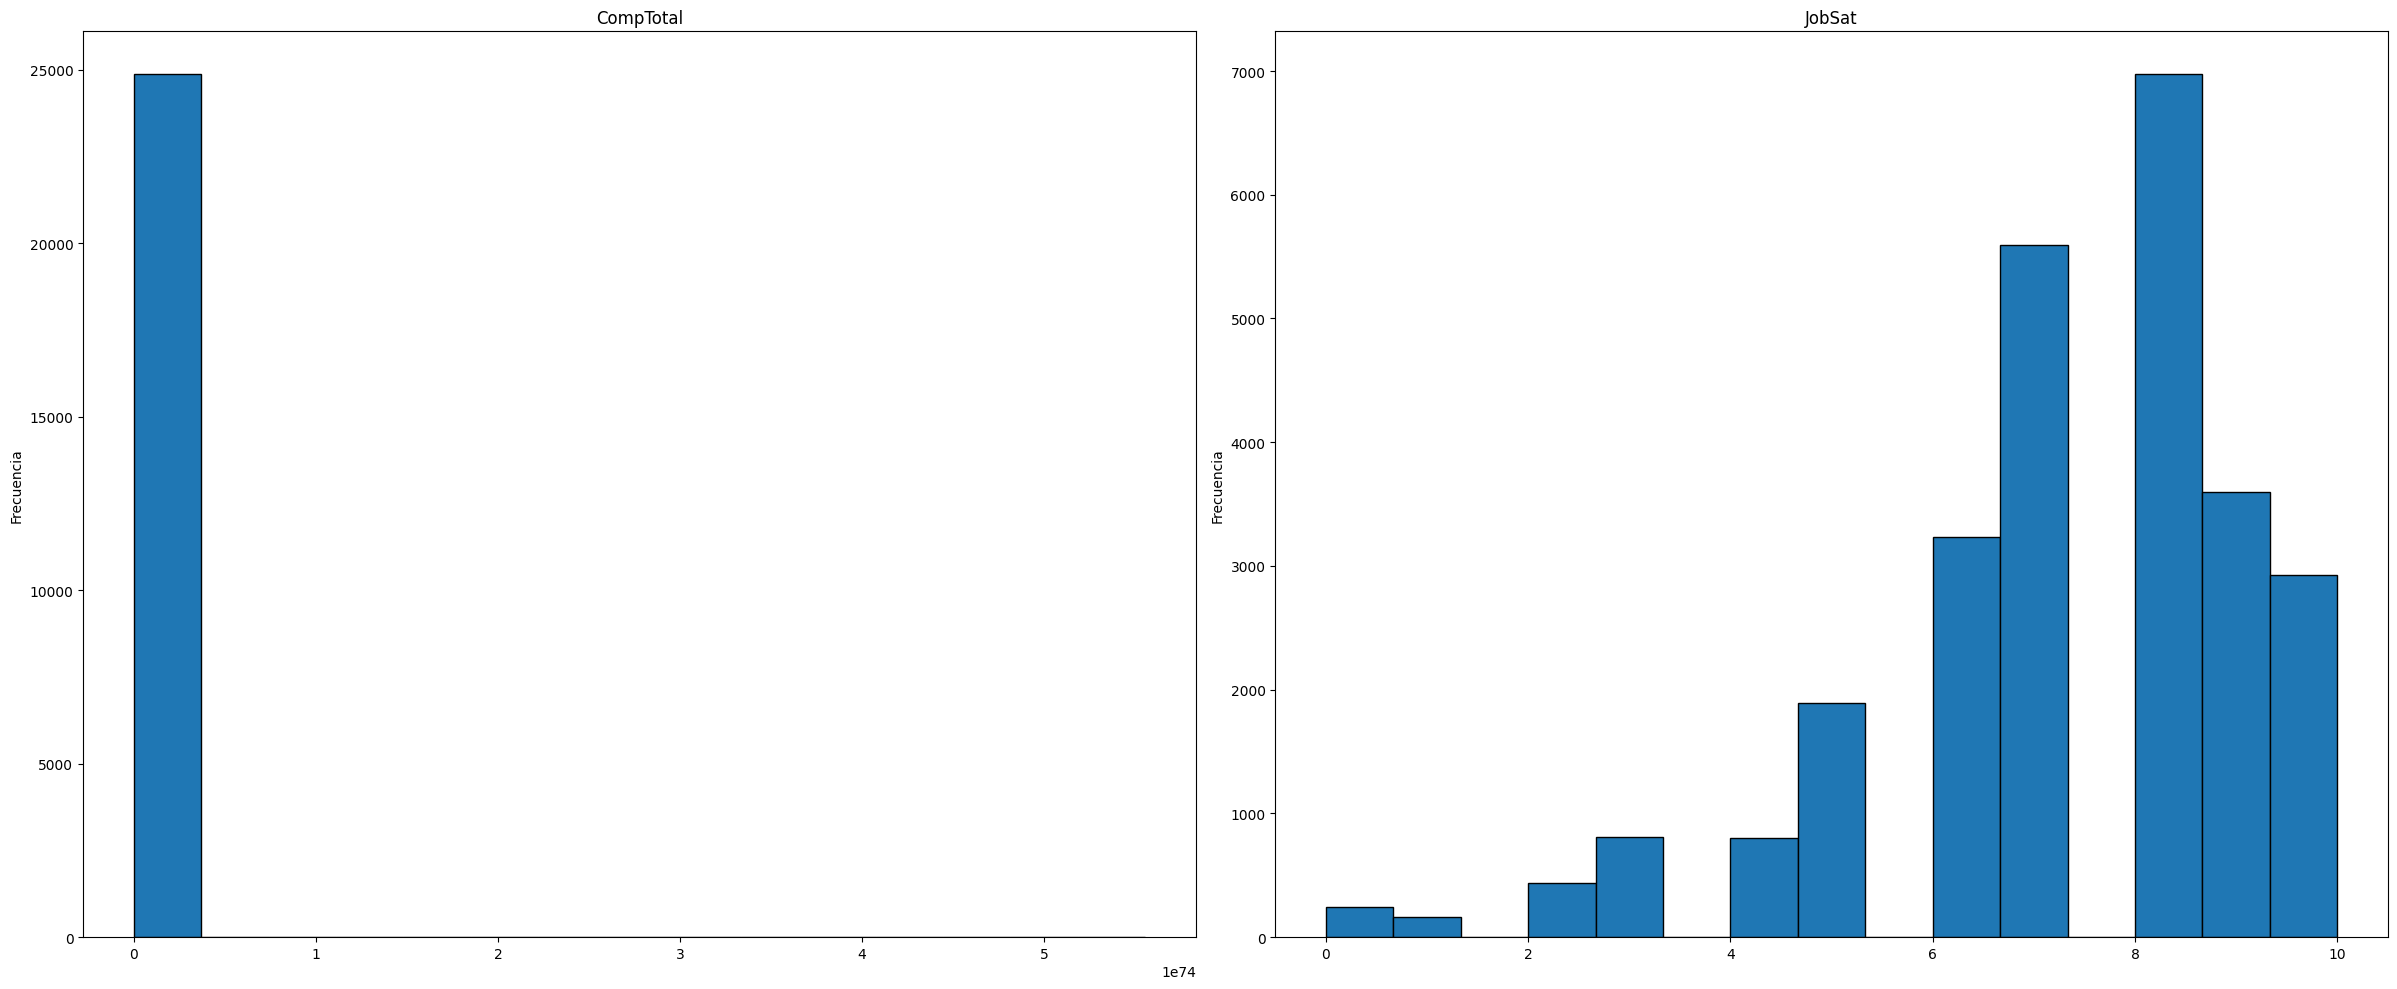

In [94]:
columnas = [
    'Age',
    'CompTotal',
    'JobSat'
]

graficar_histogramas(df, columnas)

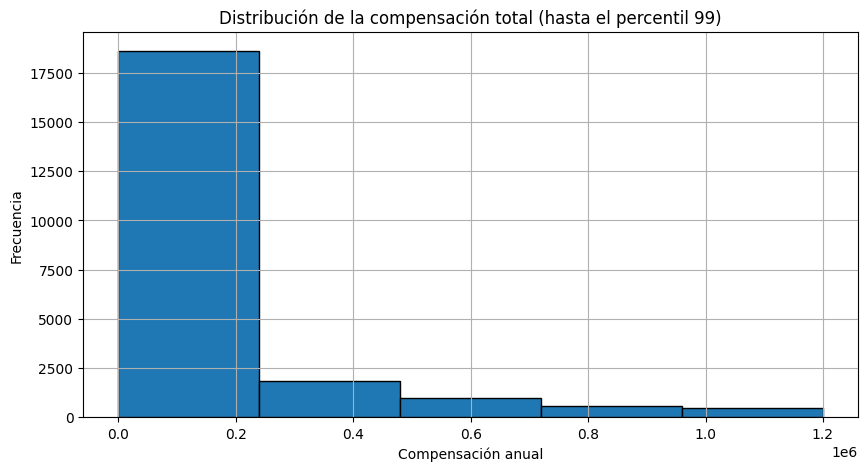

In [ ]:
comp = df['CompTotal'].dropna()
limite = comp.quantile(0.90)
comp[comp <= limite].hist(
    figsize=(10, 5),
    bins=5,
    edgecolor='black'
)
plt.title('Distribución de la compensación total (hasta el percentil 99)')
plt.xlabel('Compensación anual')
plt.ylabel('Frecuencia')
plt.show()

In [76]:
comp = df['CompTotal'].dropna()

print(comp.quantile([
    0.05,
    0.15,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.999
]))

0.050    1.400000e+03
0.150    3.600000e+04
0.250    5.500000e+04
0.500    1.050000e+05
0.750    2.400000e+05
0.900    1.200000e+06
0.950    3.600000e+06
0.990    7.266349e+07
0.999    6.019533e+09
Name: CompTotal, dtype: float64


In [50]:
metadatos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   qid       139 non-null    object 
 1   qname     139 non-null    object 
 2   question  139 non-null    object 
 3   type      139 non-null    object 
 4   sub       49 non-null     object 
 5   sq_id     49 non-null     float64
dtypes: float64(1), object(5)
memory usage: 6.6+ KB


In [58]:
columnas = [
    "TechEndorse_13_TEXT",
    "TechOppose_15_TEXT",
    "JobSatPoints_15_TEXT",
    "SO_Actions_15_TEXT",
    "LanguagesHaveEntry",
    "LanguagesWantEntry",
    "DatabaseHaveEntry",
    "DatabaseWantEntry",
    "PlatformHaveEntry",
    "PlatformWantEntry",
    "WebframeHaveEntry",
    "WebframeWantEntry",
    "DevEnvHaveEntry",
    "DevEnvWantEntry",
    "SOTagsHaveEntry",
    "SOTagsWant Entry",
    "OfficeStackHaveEntry",
    "OfficeStackWantEntry",
    "CommPlatformHaveEntr",
    "CommPlatformWantEntr",
    "AIModelsHaveEntry",
    "AIModelsWantEntry",
    "AIAgentKnowWrite",
    "AIAgentOrchWrite",
    "AIAgentObsWrite",
    "AIAgentExtWrite",
    "AIExplain",
    "AIOpen"
]

for i in columnas:
    print(f"{i}:")
    print(metadatos.loc[metadatos['qname'] == i, ['type', 'sub']])

TechEndorse_13_TEXT:
   type                             sub
10   RO  Other (please specify): - Text
TechOppose_15_TEXT:
   type                             sub
21   RO  Other (please specify): - Text
JobSatPoints_15_TEXT:
   type                             sub
37   RO  Other (please specify): - Text
SO_Actions_15_TEXT:
   type                       sub
48   RO  Other (write in): - Text
LanguagesHaveEntry:
   type  sub
77   TE  NaN
LanguagesWantEntry:
   type  sub
78   TE  NaN
DatabaseHaveEntry:
   type  sub
81   TE  NaN
DatabaseWantEntry:
   type  sub
82   TE  NaN
PlatformHaveEntry:
   type  sub
85   TE  NaN
PlatformWantEntry:
   type  sub
86   TE  NaN
WebframeHaveEntry:
   type  sub
89   TE  NaN
WebframeWantEntry:
   type  sub
90   TE  NaN
DevEnvHaveEntry:
   type  sub
93   TE  NaN
DevEnvWantEntry:
   type  sub
94   TE  NaN
SOTagsHaveEntry:
   type  sub
96   TE  NaN
SOTagsWant Entry:
   type  sub
97   TE  NaN
OfficeStackHaveEntry:
    type  sub
100   TE  NaN
OfficeStackWantEntry:
  

In [54]:
metadatos.head()

,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), object(119)
memory usage: 64.6+ MB


In [19]:
sub = df.loc[:, df.columns.str.endswith('TechEndorse')]

sub.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Empty DataFrame


In [ ]:
df['AIAgentChallenges'].isna().sum()

In [61]:
sub = df.loc[:, df.columns.str.startswith('LearnCodeAI')]

#sub['LanguageChoice'].value_counts()
sub.value_counts()

LearnCodeAI                                                                                                       
Yes, I learned how to use AI-enabled tools required for my job or to benefit my career                                16403
Yes, I learned how to use AI-enabled tools for my personal curiosity and/or hobbies                                   14027
No, I learned something that was not related to AI or AI enablement for my personal curiosity and/or hobbies           5282
No, I didn't spend time learning in the past year                                                                      4864
No, I learned something that was not related to AI or AI enablement as required for my job or to benefit my career     4625
Name: count, dtype: int64

In [60]:
cols = [
    "TechOppose_1",
    "TechOppose_2",
    "TechOppose_3",
    "TechOppose_5",
    "TechOppose_7",
    "TechOppose_9",
    "TechOppose_11",
    "TechOppose_13",
    "TechOppose_15",
    "TechOppose_16"
]
for i in cols:
    por = df[i].isna().mean()
    print(f"{i}: {por:.2%}")

TechOppose_1: 30.36%
TechOppose_2: 30.36%
TechOppose_3: 30.36%
TechOppose_5: 30.36%
TechOppose_7: 30.36%
TechOppose_9: 30.36%
TechOppose_11: 30.36%
TechOppose_13: 30.36%
TechOppose_15: 30.36%
TechOppose_16: 30.36%


In [63]:
j = 0
df_filtrado = df.loc[:, df.columns.str.startswith("AgentUsesGeneral")]
for i in df_filtrado.columns:
    por = df_filtrado[i].isna().mean()

    if por > 0.15:
        print(f"{i}: {por:.2%}")
        j += 1
j

AgentUsesGeneral: 88.20%


1

In [ ]:
import ydata_profiling as pp

report = pp.ProfileReport(df, minimal=True)

report.to_file("mi_reporte.html")

In [ ]:
df['AIExplain'].str.contains('No').value_counts()

In [ ]:
df.columns

In [ ]:
df.loc[:, df.columns.str.contains('Database')]

In [ ]:
df['DatabaseHaveEntry'].value_counts()

In [ ]:
j =0
df_filtrado = df.loc[:, df.columns.str.startswith("AI")]
for i in df_filtrado.columns:
    val = df_filtrado[i].isna().sum()
    #if val > 30000:
    print(f"{i}: {val}")
    j = j +1

print(f"Cantidad: {j}")